# 06 — Pipeline, parte por parte

Este notebook monta o pipeline do `PLAN.md` **um bloco de cada vez**. Cada seção explica o que o
bloco faz, por que ele existe e quais decisões tomamos nele (e quais alternativas ficaram de fora).

```
A. DADO           satélite → pré-processamento → patches → séries temporais      (utils/download_ee.py)
B. REPRESENTAÇÃO  TerraMind → embedding de cada patch em cada ano                (este notebook, seção 2)
C. MODELO         sequência de embeddings → Transformer Autoencoder → score      (próximo passo)
D. SAÍDA          mapa de anomalias → comparação com eventos reais               (depois)
```

**B e C são etapas separadas.** O TerraMind só *extrai* os embeddings: ele não é treinado aqui
(fica **congelado**). O resultado é salvo em disco como uma tabela `(recortes, anos, ...)`. O modelo
temporal (bloco C) é a rede neural que **nós** vamos treinar depois, lendo essa tabela.

Roda no computador local (CPU dá conta de 12 recortes) ou no Colab (ver a célula de instalação).

In [2]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Raiz do repositório (o notebook roda de dentro de notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(ROOT))
from utils.download_ee import carregar_amostra, baixar_amostra_amazonia, BANDAS_S2_TODAS

## 1. Bloco A — o dado que já temos

A amostra `amazonia_exploracao` (notebook 05): 12 recortes de 256 × 256 pixels de 10 m, de 2019 a
2025, composto anual (mediana sem nuvem) do Sentinel-2. Lembrete: `uniforme`, `mineracao` e
`mudou` dizem **onde olhamos**, não o que a área é.

### Decisão: 6 ou 12 bandas?

O TerraMind foi pré-treinado com as **12 bandas** do Sentinel-2 L2A. A amostra antiga tem só 6
(B2, B3, B4, B8, B11, B12). Há dois caminhos:

| opção | como | custo | risco |
|---|---|---|---|
| usar as 6 | o TerraMind aceita um subconjunto de bandas e aproveita os pesos só dessas | nenhum | o modelo nunca viu a imagem "sem" as outras 6; o embedding pode piorar |
| baixar as 12 | `bandas=BANDAS_S2_TODAS` no download; mesmos pontos (mesmo `seed`) | ~10 min de download | nenhum, é o formato original do modelo |

As bandas de 20 m e 60 m (B5, B6, B7, B8A, B9, B1) são reamostradas para a grade de 10 m.

Recomendação: baixar as 12 (célula abaixo, `BAIXAR_12_BANDAS = True`). Com as duas amostras,
dá até para comparar o efeito de tirar bandas — é um experimento barato.

In [3]:
BAIXAR_12_BANDAS = True   # True baixa a versão com 12 bandas (precisa do Earth Engine)

if BAIXAR_12_BANDAS:
    baixar_amostra_amazonia(
        nome='amazonia_exploracao_12b',
        n_por_criterio={'uniforme': 6, 'mineracao': 3, 'mudou': 3},
        anos=range(2019, 2026),
        tamanho_px=256,
        seed=42,
        bandas=BANDAS_S2_TODAS,
    )

AMOSTRA = 'amazonia_exploracao_12b' if BAIXAR_12_BANDAS else 'amazonia_exploracao'
X, mapbiomas, anos, info = carregar_amostra(AMOSTRA)
bandas = info.attrs['bandas']
print(f'{AMOSTRA}: X {X.shape} {X.dtype} | bandas {bandas}')
info

Os 12 recortes já estão em C:\Users\pedro\OneDrive\Área de Trabalho\projeto-deep-learnig\ProjetoGrassQuality\data\raw\amazonia_exploracao_12b
amazonia_exploracao_12b: X (12, 7, 256, 256, 12) uint16 | bandas ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12']


,arquivo,criterio,lon,lat,ecorregiao
0,00_uniforme.npz,uniforme,-50.394341,-2.276836,Xingu-Tocantins-Araguaia moist forests
1,01_uniforme.npz,uniforme,-52.730275,-8.145185,Tapajós-Xingu moist forests
2,02_uniforme.npz,uniforme,-50.785239,-0.744246,Marajó várzea
3,03_uniforme.npz,uniforme,-50.025039,-7.317959,Xingu-Tocantins-Araguaia moist forests
4,04_uniforme.npz,uniforme,-60.263229,-0.539928,Uatumã-Trombetas moist forests
5,05_uniforme.npz,uniforme,-54.362114,-3.344056,Tapajós-Xingu moist forests
6,06_mineracao.npz,mineracao,-57.493615,-5.179057,Madeira-Tapajós moist forests
7,07_mineracao.npz,mineracao,-56.563859,-1.632508,Uatumã-Trombetas moist forests
8,08_mineracao.npz,mineracao,-47.708267,-3.281815,Tocantins/Pindare moist forests
9,09_mudou.npz,mudou,-60.666866,1.243923,Rio Negro campinarana


### Pixels sem observação

Valor 0 no Sentinel-2 = nenhuma passagem sem nuvem naquele ano. O TerraMind não sabe disso: vai
tratar 0 como uma refletância de verdade. Antes de seguir, vale saber quanto disso existe.

In [4]:
sem_obs = (X == 0).all(axis=-1).mean(axis=(2, 3))   # fração de pixels sem observação, por recorte e ano
pd.DataFrame(sem_obs, columns=anos, index=info.arquivo).style.format('{:.0%}').background_gradient(vmin=0, vmax=0.5)

,2019,2020,2021,2022,2023,2024,2025
arquivo,,,,,,,
00_uniforme.npz,0%,0%,0%,0%,0%,0%,0%
01_uniforme.npz,0%,0%,0%,0%,0%,0%,0%
02_uniforme.npz,0%,0%,0%,0%,0%,0%,0%
03_uniforme.npz,0%,0%,0%,0%,0%,0%,0%
04_uniforme.npz,0%,0%,0%,0%,0%,0%,0%
05_uniforme.npz,0%,0%,0%,0%,0%,0%,0%
06_mineracao.npz,0%,0%,0%,0%,0%,0%,0%
07_mineracao.npz,0%,0%,0%,0%,0%,0%,0%
08_mineracao.npz,0%,0%,0%,0%,0%,0%,0%


## 2. Bloco B — TerraMind: de imagem para embedding

**O que é.** Um *foundation model* de observação da Terra (IBM + ESA, 2025), pré-treinado em
milhões de imagens de vários sensores (Sentinel-2, Sentinel-1, relevo, uso do solo...). A
arquitetura é um ViT: a imagem de 224 × 224 é cortada em pedacinhos de 16 × 16 pixels (14 × 14 =
196 pedacinhos, chamados *tokens*), e o modelo devolve **um vetor por token**. No tamanho Small,
cada vetor tem 384 números.

Na nossa escala, cada token cobre 160 m × 160 m. Então um recorte vira uma grade 14 × 14 de vetores.

**Mesma ideia do AlphaEarth, outro jeito de usar.** Os dois transformam imagem em embedding. O
AlphaEarth já vem calculado pelo Google (um vetor de 64 números por pixel por ano): só baixamos o
resultado. O TerraMind tem os pesos abertos: **nós** rodamos o modelo nas **nossas** imagens, então
controlamos a entrada (bandas, período do composto, tamanho do recorte).

**Congelado × fine-tuning.**
- *Congelado*: usamos os pesos como vieram, só para extrair embeddings. Nada é treinado.
- *Fine-tuning*: continuamos treinando os pesos com os nossos dados, para uma tarefa nossa. Precisa
  de um objetivo de treino (rótulos ou uma tarefa auto-supervisionada) e de GPU.

Aqui usamos **congelado**: não temos rótulos e queremos uma representação geral, que o bloco C vai
usar para aprender o "normal". Fine-tuning fica como variação para depois.

### Instalação

O TerraMind vem no pacote `terratorch` (IBM). Localmente: `pip install terratorch` no `.venv`. No
Colab, descomente a célula abaixo.

In [5]:
# !pip install -q terratorch

### Pré-processamento que o modelo exige

1. **Nome das bandas.** O TerraMind chama as bandas por nome (`BLUE`, `RED`, ...), não por código.
2. **Padronização.** Cada banda vira `(valor - média) / desvio`, com a média e o desvio **do
   pré-treino** (valores de `terramind_register.py` no repositório do terratorch). Se usarmos outra
   escala, o modelo recebe números que nunca viu.
3. **Tamanho.** O modelo foi treinado com 224 × 224. Nossos recortes têm 256 × 256: cortamos o
   centro (perdemos 16 pixels de cada borda; o ponto sorteado continua no meio).

In [6]:
# Código do Sentinel-2 -> nome no TerraMind, na ordem do pré-treino (S2L2A)
NOME_TERRAMIND = {'B1': 'COASTAL_AEROSOL', 'B2': 'BLUE', 'B3': 'GREEN', 'B4': 'RED',
                  'B5': 'RED_EDGE_1', 'B6': 'RED_EDGE_2', 'B7': 'RED_EDGE_3', 'B8': 'NIR_BROAD',
                  'B8A': 'NIR_NARROW', 'B9': 'WATER_VAPOR', 'B11': 'SWIR_1', 'B12': 'SWIR_2'}
# Média e desvio do pré-treino (refletância × 10000), mesma ordem
MEDIA_PRETREINO = [1390.458, 1503.317, 1718.197, 1853.91, 2199.1, 2779.975,
                   2987.011, 3083.234, 3132.22, 3162.988, 2424.884, 1857.648]
DESVIO_PRETREINO = [2106.761, 2141.107, 2038.973, 2134.138, 2085.321, 1889.926,
                    1820.257, 1871.918, 1753.829, 1797.379, 1434.261, 1334.311]
ORDEM = list(NOME_TERRAMIND)

idx = [ORDEM.index(b) for b in bandas]
media = np.array(MEDIA_PRETREINO, dtype=np.float32)[idx]
desvio = np.array(DESVIO_PRETREINO, dtype=np.float32)[idx]
nomes_tm = [NOME_TERRAMIND[b] for b in bandas]

TAMANHO = 224


def preparar(imagens):
    """(n, H, W, bandas) uint16 -> tensor (n, bandas, 224, 224) padronizado, recorte central."""
    h, w = imagens.shape[1:3]
    y0, x0 = (h - TAMANHO) // 2, (w - TAMANHO) // 2
    a = imagens[:, y0:y0 + TAMANHO, x0:x0 + TAMANHO].astype(np.float32)
    a = (a - media) / desvio
    return torch.from_numpy(a).permute(0, 3, 1, 2)


print('Bandas para o TerraMind:', nomes_tm)

Bandas para o TerraMind: ['COASTAL_AEROSOL', 'BLUE', 'GREEN', 'RED', 'RED_EDGE_1', 'RED_EDGE_2', 'RED_EDGE_3', 'NIR_BROAD', 'NIR_NARROW', 'WATER_VAPOR', 'SWIR_1', 'SWIR_2']


In [7]:
import torch
from terratorch import BACKBONE_REGISTRY

dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'
modelo = BACKBONE_REGISTRY.build(
    'terramind_v1_small',
    pretrained=True,              # baixa os pesos do Hugging Face na primeira vez
    modalities=['S2L2A'],
    bands={'S2L2A': nomes_tm},    # avisa quais bandas estamos passando (todas as 12 ou um subconjunto)
).to(dispositivo).eval()          # eval(): modo de inferência, sem treino
print('Parâmetros:', sum(p.numel() for p in modelo.parameters()) / 1e6, 'milhões | dispositivo:', dispositivo)

c:\Users\pedro\OneDrive\Área de Trabalho\projeto-deep-learnig\ProjetoGrassQuality\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\pedro\OneDrive\Área de Trabalho\projeto-deep-learnig\ProjetoGrassQuality\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Parâmetros: 22.464768 milhões | dispositivo: cpu


### Primeiro teste: um recorte, um ano

Antes de rodar tudo, olhar o formato da saída. Esperado: `(1, 196, 384)` = 1 imagem, 196 tokens,
384 números por token.

In [8]:
@torch.no_grad()   # sem gradiente: não estamos treinando, só extraindo
def embeddings(imagens, lote=8):
    """(n, H, W, bandas) -> (n, 196, D) embeddings dos tokens."""
    saidas = []
    for i in range(0, len(imagens), lote):
        x = preparar(imagens[i:i + lote]).to(dispositivo)
        z = modelo({'S2L2A': x})
        if isinstance(z, (list, tuple)):   # alguns backbones do terratorch devolvem uma saída por camada
            z = z[-1]                      # ficamos com a última
        saidas.append(z.float().cpu().numpy())
    return np.concatenate(saidas)


z = embeddings(X[0, :1])
print('saída:', z.shape)

saída: (1, 196, 384)


### Todos os recortes, todos os anos → a tabela do bloco C

Resultado: `tokens` com forma `(recortes, anos, 14, 14, D)`. Salvamos em `data/processed/` (fora do
git), junto com a origem de cada recorte e as escolhas feitas aqui, para o bloco C só ler o arquivo.

In [9]:
n, t = X.shape[:2]
lado = TAMANHO // 16
z = embeddings(X.reshape(n * t, *X.shape[2:]))            # (n * anos, 196, D)
tokens = z.reshape(n, t, lado, lado, -1).astype(np.float16)
print('tokens:', tokens.shape)

saida = ROOT / 'data' / 'processed' / f'{AMOSTRA}_terramind_small.npz'
saida.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    saida, tokens=tokens, anos=np.array(anos), arquivo=info.arquivo.values, criterio=info.criterio.values,
    lon=info.lon.values, lat=info.lat.values, sem_obs=sem_obs,
    escolhas=json.dumps({'modelo': 'terramind_v1_small', 'congelado': True, 'bandas': bandas,
                         'recorte': f'centro {TAMANHO}x{TAMANHO}', 'padronizacao': 'media/desvio do pre-treino',
                         'saida': 'ultima camada'}))
print('salvo em', saida)

tokens: (12, 7, 14, 14, 384)
salvo em c:\Users\pedro\OneDrive\Área de Trabalho\projeto-deep-learnig\ProjetoGrassQuality\data\processed\amazonia_exploracao_12b_terramind_small.npz


### Primeira olhada: o embedding muda quando a área muda?

Mesma pergunta do experimento do Gabriel, agora com o TerraMind. Para cada recorte, a **mudança
de um ano para o seguinte** = distância cosseno entre os embeddings (0 = igual). Duas versões:

- **recorte inteiro**: média dos 196 tokens (um vetor por recorte e ano);
- **token central**: só os 160 m em volta do ponto sorteado (onde o critério foi checado).

Se a ideia do pipeline funciona, `mineracao` e `mudou` deveriam ter picos que `uniforme` não tem.
Com 12 recortes isso é só uma intuição, não um resultado.

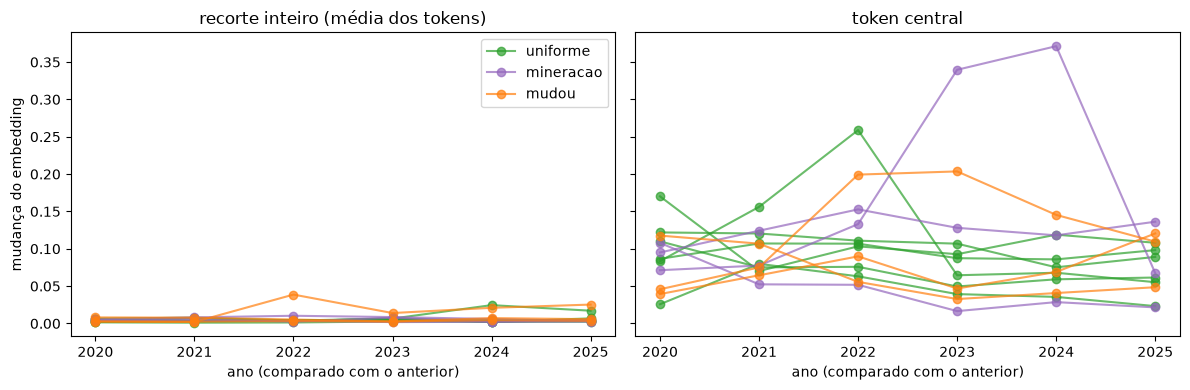

In [10]:
def distancia_cosseno_anual(v):
    """v: (anos, D) -> distância cosseno entre anos consecutivos (anos - 1,)."""
    v = v / np.linalg.norm(v, axis=-1, keepdims=True)
    return 1 - (v[1:] * v[:-1]).sum(-1)


tok = tokens.astype(np.float32)
c = lado // 2
versoes = {'recorte inteiro (média dos tokens)': tok.mean(axis=(2, 3)),
           'token central': tok[:, :, c, c]}
cores = {'uniforme': 'tab:green', 'mineracao': 'tab:purple', 'mudou': 'tab:orange'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (titulo, v) in zip(axes, versoes.items()):
    for i in range(n):
        ax.plot(anos[1:], distancia_cosseno_anual(v[i]), marker='o', alpha=0.7,
                color=cores.get(info.criterio[i], 'gray'), label=info.criterio[i])
    ax.set_title(titulo)
    ax.set_xlabel('ano (comparado com o anterior)')
axes[0].set_ylabel('mudança do embedding')
h, l = axes[0].get_legend_handles_labels()
axes[0].legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys())
plt.tight_layout()
plt.show()

### Onde, dentro do recorte, o embedding mudou?

Para um recorte, a imagem do primeiro e do último ano e o **mapa de mudança por token** (distância
cosseno entre os dois anos em cada um dos 14 × 14 tokens). É um rascunho do "mapa de anomalias" do
bloco D, mas aqui medindo só mudança, não anomalia.

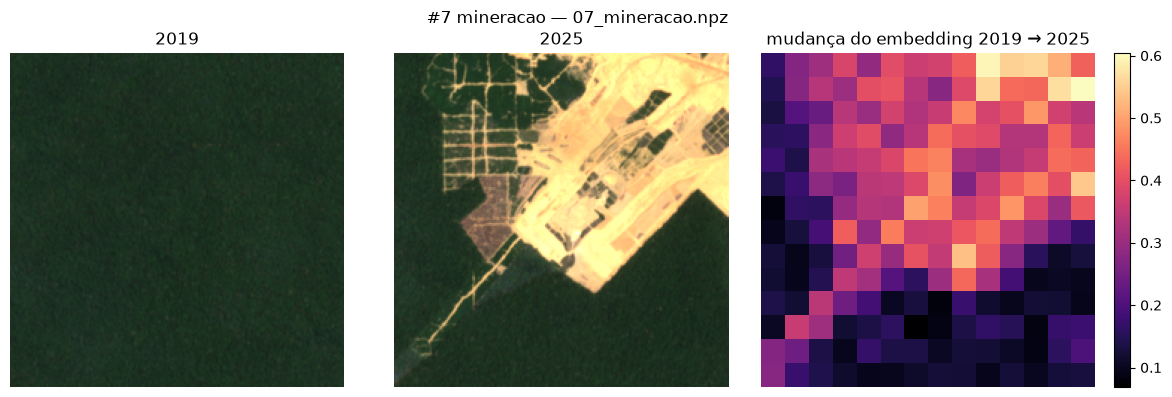

In [12]:
def rgb(img, ganho=3.5):
    """(H, W, bandas) uint16 -> RGB em [0, 1], usando os nomes das bandas."""
    a = img[..., [bandas.index('B4'), bandas.index('B3'), bandas.index('B2')]] / 10000 * ganho
    return np.clip(a, 0, 1)


def mapa_mudanca(i, a0=0, a1=-1):
    v0, v1 = tok[i, a0], tok[i, a1]
    v0 = v0 / np.linalg.norm(v0, axis=-1, keepdims=True)
    v1 = v1 / np.linalg.norm(v1, axis=-1, keepdims=True)
    return 1 - (v0 * v1).sum(-1)


i = int(np.where(info.criterio == 'mineracao')[0][1])   
y0 = (X.shape[2] - TAMANHO) // 2
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(rgb(X[i, 0, y0:y0 + TAMANHO, y0:y0 + TAMANHO]))
axes[0].set_title(f'{anos[0]}')
axes[1].imshow(rgb(X[i, -1, y0:y0 + TAMANHO, y0:y0 + TAMANHO]))
axes[1].set_title(f'{anos[-1]}')
im = axes[2].imshow(mapa_mudanca(i), cmap='magma')
axes[2].set_title(f'mudança do embedding {anos[0]} → {anos[-1]}')
plt.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.axis('off')
fig.suptitle(f'#{i} {info.criterio[i]} — {info.arquivo[i]}')
plt.tight_layout()
plt.show()

## Próximo: bloco C

Com `tokens` salvo, o bloco C lê o arquivo e treina um modelo que aprende como a sequência de
embeddings **normalmente** evolui. Decisões que vamos discutir lá:

- usar o vetor do recorte inteiro ou cada token como uma série separada (196 séries por recorte);
- o que conta como "normal" no treino;
- começar por um baseline simples (distância ano a ano, Isolation Forest) antes do Transformer;
- 12 recortes não treinam nada: o bloco C vai pedir mais dado do tipo "normal".